# **CVC-ClinicDB Dataset**

In [1]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [3]:
cfg = TrainConfig(
    # --- General ---
    model_name = "UNet",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [4]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [5]:
model = UNet(n_channels=3, n_classes=1, base_channels=32, bilinear=False)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-05 23:35:09 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | Logging to model_comparisons/logs/UNet_model_CVC_ClinicDB_20250905_233509.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-05 23:35:10 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/96lsku60
100%|██████████| 8/8 [00:01<00:00,  7.57it/s]
2025-09-05 23:35:17 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | Epoch 001/100 | Train: 1.384134 | Val: 1.332688 | LR: 0.000100 | 7.24s | Val Dice: 0.3406 IoU: 0.2275 F1: 0.3872
2025-09-05 23:35:17 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | Saved best: model_comparisons/models/best_UNet_model_CVC_ClinicDB_20250905_233509.pth (val=1.332688)
100%|██████████| 8/8 [00:00<00:00, 14.04it/s]
2025-09-05 23:35:24 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | Epoch 002/100 | Train: 1.239570 | Val: 1.214211 | LR: 0.000100 | 6.00s | Val Dice: 0.3596 IoU: 0.2583 F1: 0.4787
2025-09-05 23:35:24 | INFO | UNet_model_CVC_ClinicDB_20250905_233509 | Saved best: model_comparisons/models/best_UNet_model_CVC_ClinicDB_20250905_233509.pth (val=1.214211)
100%|██████████| 8/8 [00:00<00:00, 11.32it/s]
202

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▆▃▅▆▇▆▃▅▂▅▄█▇▂▄▄▅▂█▄▂▄▂▄▁█▇▂█▂▇▄▄▅▄▅▅▅▅▄
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▃▆▄▃▂▃▄▇▇▅▄▁▂▇▇▅▇▄▇▁▄▇▇▂▅▄█▂▁▁▁▄▄▄▅▄▄▃▄▄
epoch_seconds,▇▁▂▃▄▂▇▃▃▂▃▄▃▅▆▃▃▃▄▃▄▃▃▃█▃▃▄▃▃▄▃▃▃▃▄▃▃▂▃
lr,█████████████████████████▃▃▃▃▃▃▃▃▃▃▃▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▃▃▄▄▆▆▇▇▇▇▇▇▇██████▇▇▇█████████████████
train/f1,▁▃▄▄▆▆▆▇▇▇▇▇▇▇▇███████▇▇▇███████████████
train/iou,▁▁▃▃▄▅▅▅▆▆▆▇▆▇▆▇▇▇▇▇██▇▇▇▇██████████████
+11,...


{'best_val_loss': 0.2685967367142439,
 'epochs_ran': 61,
 'best_model_path': 'model_comparisons/models/best_UNet_model_CVC_ClinicDB_20250905_233509.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_UNet_CVC_ClinicDB_20250905_233509.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/96lsku60',
 'log_path': 'model_comparisons/logs/UNet_model_CVC_ClinicDB_20250905_233509.log'}

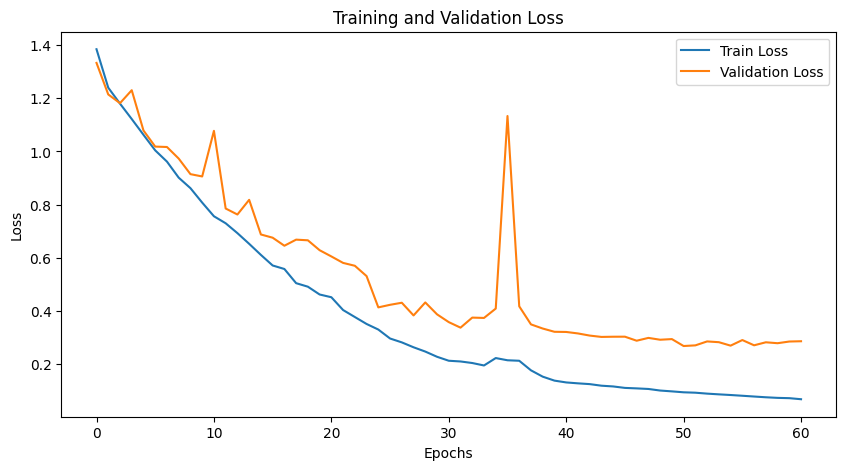

In [6]:
trainer.plot_losses()

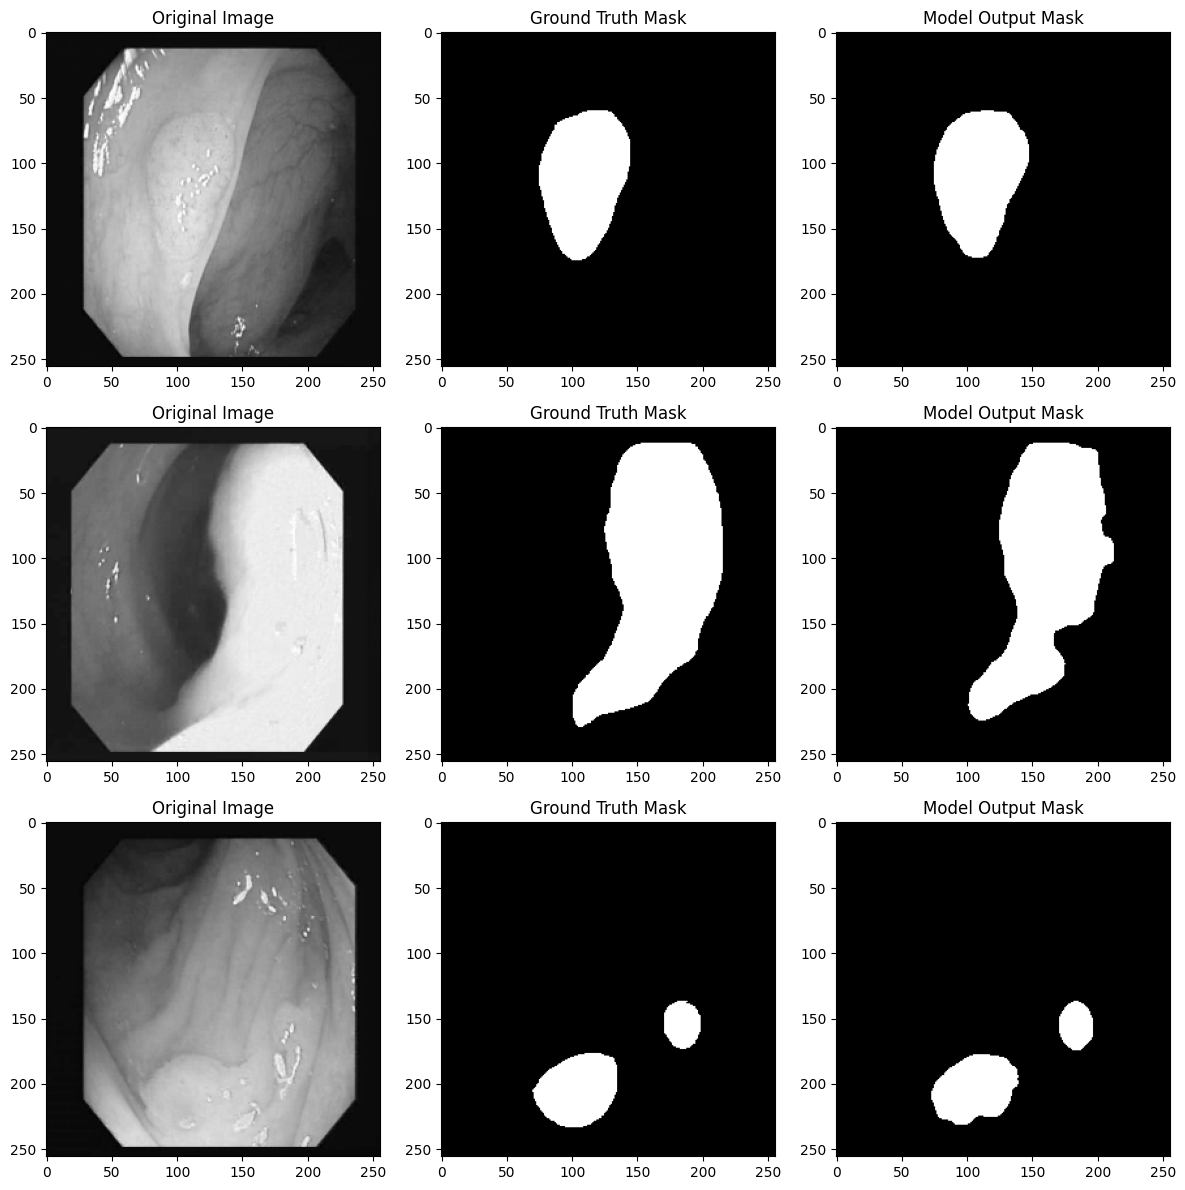

In [7]:
trainer.visualize_output_samples()

In [8]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00, 10.52it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.2866
Average Dice Score                 : 0.8231
Average Hausdorff Distance         : inf
Average IoU                        : 0.7481
Precision                          : 0.9624
Recall                             : 0.7788
F1 Score                           : 0.8609
IoU (batch avg)                    : 0.7486
Dice (batch avg)                   : 0.8515
Total Parameters                   : 7,763,041
Trainable Parameters               : 7,763,041
Average Inference Time (seconds)   : 0.016025
FPS (Frames Per Second)            : 62.40
FLOPs                              : 13,745,782,784.0
GFLOPs                             : 13.7458

Results saved to: model_comparisons/evaluation_results/UNet_model_CVC-ClinicDB_evaluation_results_20250905_233509.csv
Validation results saved to model_comparisons/evaluation_results/UNet_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.28658245503902435,
 'avg_dice_score': 0.8230571882667282,
 'avg_hd_score': inf,
 'avg_iou': 0.7481074243111198,
 'precision': 0.9623736686380074,
 'recall': 0.7788362785401844,
 'f1': 0.8609318225660064,
 'iou_batch_avg': 0.7486429139971733,
 'dice_batch_avg': 0.8514565005898476,
 'total_params': 7763041,
 'trainable_params': 7763041,
 'avg_inference_time': 0.01602466106414795,
 'fps': 62.4038159682082,
 'flops': 13745782784.0,
 'gflops': 13.745782784}

# **Kvasir-SEG dataset**

In [9]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [11]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


# UNet Kvasir training config

In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "UNet",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = UNet(n_channels=3, n_classes=1, base_channels=32, bilinear=False)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-05 23:47:42 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | Logging to model_comparisons/logs/UNet_model_Kvasir_SEG_20250905_234742.log


2025-09-05 23:47:43 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/4jkkb26n
100%|██████████| 13/13 [00:03<00:00,  4.26it/s]
2025-09-05 23:47:55 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | Epoch 001/100 | Train: 1.165901 | Val: 1.078266 | LR: 0.000100 | 12.01s | Val Dice: 0.5399 IoU: 0.4097 F1: 0.5823
2025-09-05 23:47:55 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | Saved best: model_comparisons/models/best_UNet_model_Kvasir_SEG_20250905_234742.pth (val=1.078266)
100%|██████████| 13/13 [00:03<00:00,  3.65it/s]
2025-09-05 23:48:08 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | Epoch 002/100 | Train: 1.010185 | Val: 0.986996 | LR: 0.000100 | 12.34s | Val Dice: 0.5513 IoU: 0.4266 F1: 0.6098
2025-09-05 23:48:08 | INFO | UNet_model_Kvasir_SEG_20250905_234742 | Saved best: model_comparisons/models/best_UNet_model_Kvasir_SEG_20250905_234742.pth (val=0.986996)
100%|██████████| 13/13 [00:03<00:00,  3.49it/s]
2025-09-0

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▃▃▁▃▁▁▂▁▃▁▃▅▁▁▅▃▁▃▁▃▁█▃██▆▅▅▃▆▇▇▇▇██
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▆▅▇▆██▇█▅█▆▄██▃▅█▆█▆█▁▆▁▁▃▄▄▅▃▁▂▂▂▁▁
epoch_seconds,▇██▆▅▇▄▅▅▅▆▇▅▄▇▆▅▃▃▄▄▂▃▁▅▁▂▃▂▃▄▁▁▂▂▃
lr,████████████████████████▃▃▃▃▃▃▃▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▃▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇█████████████
train/f1,▁▃▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇█████████████
train/iou,▁▂▃▃▃▄▄▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇███████████
+11,...


{'best_val_loss': 0.4210018687523328,
 'epochs_ran': 36,
 'best_model_path': 'model_comparisons/models/best_UNet_model_Kvasir_SEG_20250905_234742.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_UNet_Kvasir_SEG_20250905_234742.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/4jkkb26n',
 'log_path': 'model_comparisons/logs/UNet_model_Kvasir_SEG_20250905_234742.log'}

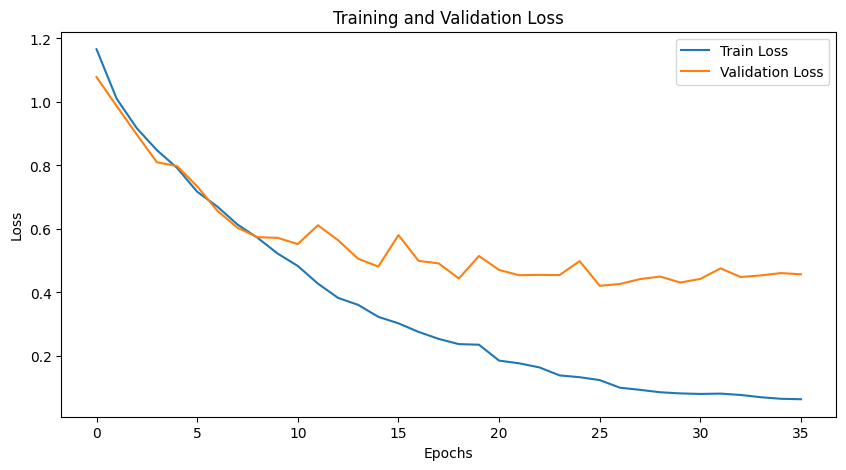

In [15]:
trainer.plot_losses()

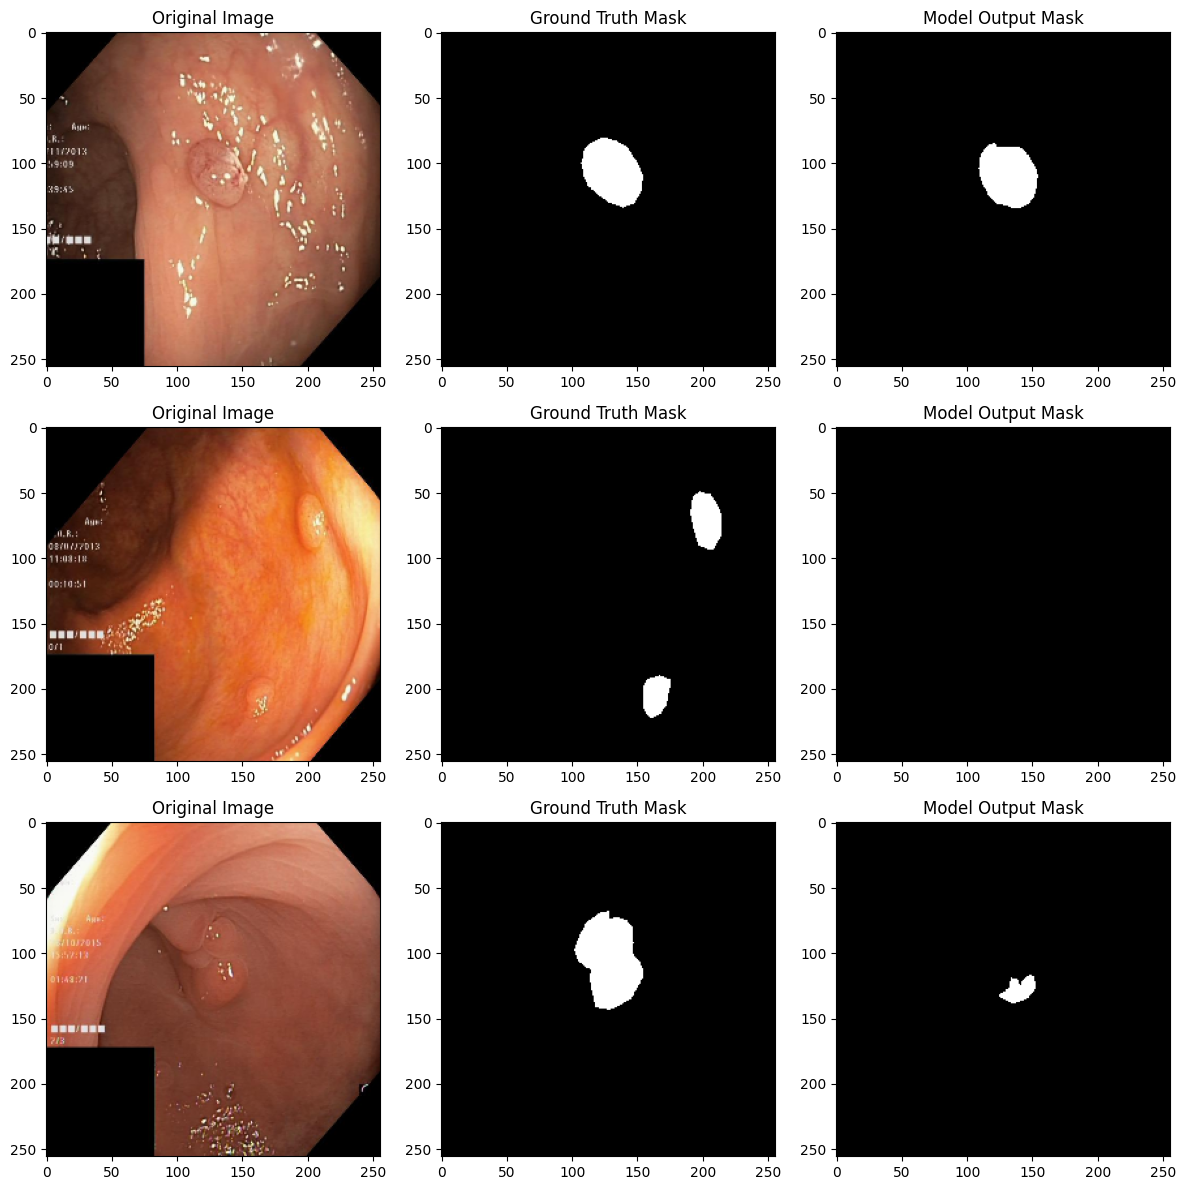

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:02<00:00,  6.20it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4571
Average Dice Score                 : 0.7734
Average Hausdorff Distance         : inf
Average IoU                        : 0.6810
Precision                          : 0.8835
Recall                             : 0.7158
F1 Score                           : 0.7909
IoU (batch avg)                    : 0.6685
Dice (batch avg)                   : 0.7937
Total Parameters                   : 7,763,041
Trainable Parameters               : 7,763,041
Average Inference Time (seconds)   : 0.014616
FPS (Frames Per Second)            : 68.42
FLOPs                              : 13,745,782,784.0
GFLOPs                             : 13.7458

Results saved to: model_comparisons/evaluation_results/UNet_model_Kvasir-SEG_evaluation_results_20250905_234742.csv
Validation results saved to model_comparisons/evaluation_results/UNet_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.4571451120651685,
 'avg_dice_score': 0.7733680793195075,
 'avg_hd_score': inf,
 'avg_iou': 0.6809690890665209,
 'precision': 0.883531492678952,
 'recall': 0.7157858086615607,
 'f1': 0.7908615800442845,
 'iou_batch_avg': 0.6685169958151304,
 'dice_batch_avg': 0.7936968986804669,
 'total_params': 7763041,
 'trainable_params': 7763041,
 'avg_inference_time': 0.014616265296936035,
 'fps': 68.41693002176329,
 'flops': 13745782784.0,
 'gflops': 13.745782784}